In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import Sequence

from tensorflow.keras.applications import (
    ResNet50,
    VGG19,
    VGG16,
    InceptionV3
)

from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [ ]:
base_path = "/content/drive/MyDrive/AI Course2/HW 2-13/Brain_Tumor"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 4

In [ ]:
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(validation_split=0.2)
test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow_from_directory(
    base_path + "/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    base_path + "/Training",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

test_generator = test_datagen.flow_from_directory(
    base_path + "/Testing",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 2310 images belonging to 4 classes.
Found 576 images belonging to 4 classes.
Found 394 images belonging to 4 classes.


In [ ]:
preprocess_functions = {
    "ResNet50": resnet_preprocess,
    "VGG19": vgg_preprocess,
    "VGG16": vgg_preprocess,
    "InceptionV3": inception_preprocess
}

In [ ]:
class PreprocessedGenerator(Sequence):
    def __init__(self, generator, preprocess_function, **kwargs):
        super().__init__(**kwargs)
        self.generator = generator
        self.preprocess_function = preprocess_function

    def __len__(self):
        return len(self.generator)

    def __getitem__(self, index):
        images, labels = self.generator[index]
        images = self.preprocess_function(images.copy())
        return images, labels

    def on_epoch_end(self):
        self.generator.on_epoch_end()

In [ ]:
train_generators = {
    name: PreprocessedGenerator(train_generator, preprocess_functions[name])
    for name in preprocess_functions
}

val_generators = {
    name: PreprocessedGenerator(val_generator, preprocess_functions[name])
    for name in preprocess_functions
}

test_generators = {
    name: PreprocessedGenerator(test_generator, preprocess_functions[name])
    for name in preprocess_functions
}

In [ ]:
def build_model(base_model_fn, model_name):
    base_model = base_model_fn(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMG_SIZE, 3)
    )

    for layer in base_model.layers:
        layer.trainable = False

    conv_layers = [
        layer for layer in base_model.layers
        if isinstance(layer, tf.keras.layers.Conv2D)
    ]

    for layer in conv_layers[-2:]:
        layer.trainable = True

    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    output = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return Model(
        inputs=base_model.input,
        outputs=output,
        name=model_name
    )

In [ ]:
resnet_model = build_model(ResNet50, "ResNet50")
vgg19_model = build_model(VGG19, "VGG19")
vgg16_model = build_model(VGG16, "VGG16")
inception_model = build_model(InceptionV3, "InceptionV3")

models = {
    "ResNet50": resnet_model,
    "VGG19": vgg19_model,
    "VGG16": vgg16_model,
    "InceptionV3": inception_model
}

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_generator.classes)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_generator.classes
)

class_weights = dict(zip(classes, class_weights_array))

class_weights

{np.int32(0): np.float64(0.8736762481089259),
 np.int32(1): np.float64(0.860655737704918),
 np.int32(2): np.float64(1.8275316455696202),
 np.int32(3): np.float64(0.872356495468278)}

In [ ]:
for model in models.values():
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

In [ ]:
histories = {}

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")

    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )

    history = model.fit(
        train_generators[model_name],
        validation_data=val_generators[model_name],
        epochs=100,
        class_weight=class_weights,
        callbacks=[early_stopping, reduce_lr]
    )

    histories[model_name] = history


Training ResNet50...
Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1735s 24s/step - accuracy: 0.6134 - loss: 0.9534 - val_accuracy: 0.7500 - val_loss: 0.6287 - learning_rate: 1.0000e-04
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 46s 626ms/step - accuracy: 0.7900 - loss: 0.5072 - val_accuracy: 0.7760 - val_loss: 0.5808 - learning_rate: 1.0000e-04
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 45s 618ms/step - accuracy: 0.8632 - loss: 0.3401 - val_accuracy: 0.8056 - val_loss: 0.5379 - learning_rate: 1.0000e-04
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 48s 654ms/step - accuracy: 0.8615 - loss: 0.3218 - val_accuracy: 0.7917 - val_loss: 0.5274 - learning_rate: 1.0000e-04
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 54s 738ms/step - accuracy: 0.8874 - loss: 0.2736 - val_accuracy: 0.7587 - val_loss: 0.5857 - learning_rate: 1.0000e-04
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 53s 719ms/step - accuracy: 0.8970 - loss: 0.2468 - val_accuracy: 0.8333 - val_loss: 0.5054 - learning_rate: 1.0000e-04
Epoch 7/100
73/73 ━━━━━━━━━━━━

In [ ]:
test_results = {}

for model_name, model in models.items():
    loss, accuracy = model.evaluate(
        test_generators[model_name],
        verbose=1
    )

    test_results[model_name] = {
        "loss": loss,
        "accuracy": accuracy
    }

    print(f"{model_name} - Loss: {loss:.4f} | Accuracy: {accuracy:.4f}")

13/13 ━━━━━━━━━━━━━━━━━━━━ 221s 18s/step - accuracy: 0.6827 - loss: 1.7463
ResNet50 - Loss: 1.7463 | Accuracy: 0.6827
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 432ms/step - accuracy: 0.6980 - loss: 1.3587
VGG19 - Loss: 1.3587 | Accuracy: 0.6980
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 231ms/step - accuracy: 0.7081 - loss: 1.5261
VGG16 - Loss: 1.5261 | Accuracy: 0.7081
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 784ms/step - accuracy: 0.7183 - loss: 1.0914
InceptionV3 - Loss: 1.0914 | Accuracy: 0.7183


In [14]:
reports = {}

for model_name, model in models.items():
    y_pred_probs = model.predict(
        test_generators[model_name],
        verbose=0
    )

    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = test_generator.classes

    reports[model_name] = classification_report(
        y_true,
        y_pred,
        target_names=list(test_generator.class_indices.keys()),
        output_dict=True
    )

    print(f"\n{'=' * 50}")
    print(model_name)
    print('=' * 50)

    print(
        classification_report(
            y_true,
            y_pred,
            target_names=list(test_generator.class_indices.keys())
        )
    )


ResNet50
                  precision    recall  f1-score   support

    glioma_tumor       0.88      0.21      0.34       100
meningioma_tumor       0.58      0.94      0.72       115
        no_tumor       0.71      0.93      0.81       105
 pituitary_tumor       0.93      0.57      0.71        74

        accuracy                           0.68       394
       macro avg       0.77      0.66      0.64       394
    weighted avg       0.76      0.68      0.64       394


VGG19
                  precision    recall  f1-score   support

    glioma_tumor       0.90      0.19      0.31       100
meningioma_tumor       0.69      0.89      0.78       115
        no_tumor       0.60      0.98      0.74       105
 pituitary_tumor       0.96      0.69      0.80        74

        accuracy                           0.70       394
       macro avg       0.79      0.69      0.66       394
    weighted avg       0.77      0.70      0.66       394


VGG16
                  precision    recall  f1-

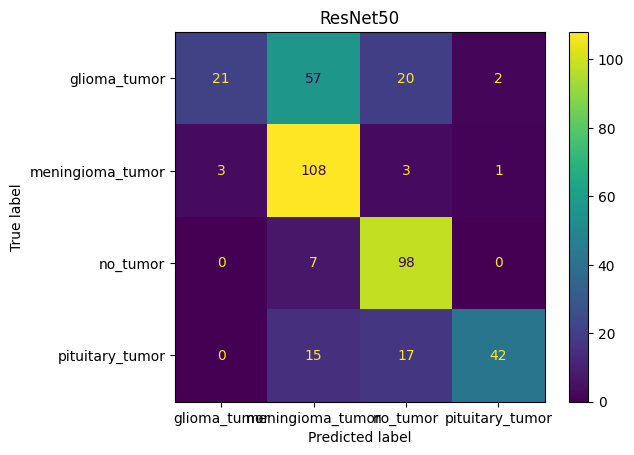

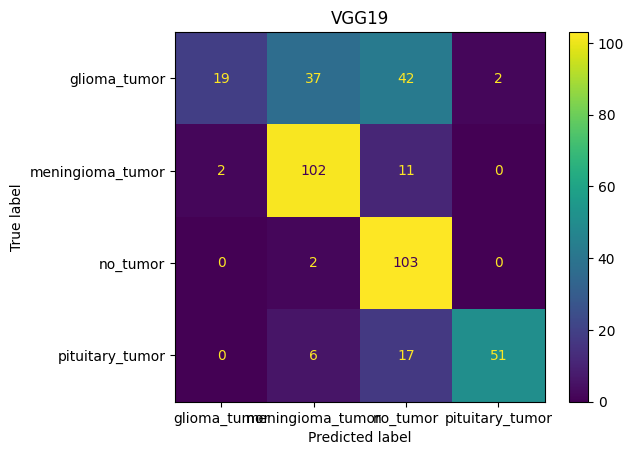

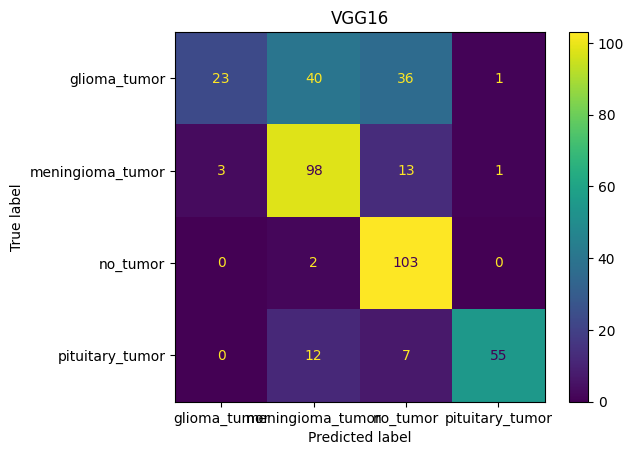

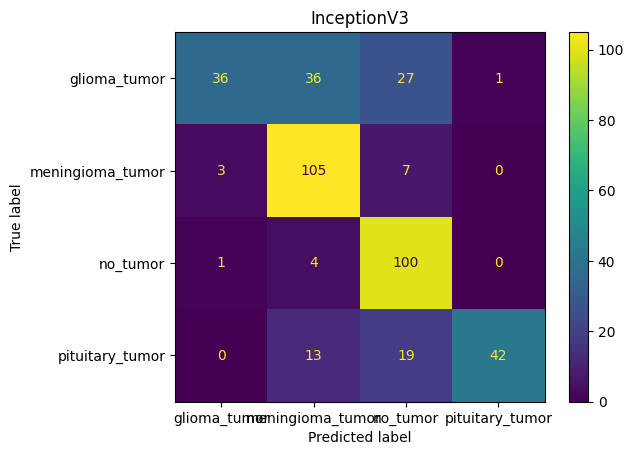

In [15]:
for model_name, model in models.items():
    y_pred_probs = model.predict(
        test_generators[model_name],
        verbose=0
    )

    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = test_generator.classes

    cm = confusion_matrix(y_true, y_pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=test_generator.class_indices.keys()
    ).plot()

    plt.title(model_name)
    plt.show()

In [16]:
comparison = []

for model_name in models:
    comparison.append({
        "Model": model_name,
        "Accuracy": test_results[model_name]["accuracy"],
        "Macro F1": reports[model_name]["macro avg"]["f1-score"]
    })

comparison

[{'Model': 'ResNet50',
  'Accuracy': 0.682741105556488,
  'Macro F1': 0.6416020451449799},
 {'Model': 'VGG19',
  'Accuracy': 0.6979695558547974,
  'Macro F1': 0.6592080853797874},
 {'Model': 'VGG16',
  'Accuracy': 0.7081218361854553,
  'Macro F1': 0.6797898622186725},
 {'Model': 'InceptionV3',
  'Accuracy': 0.7182741165161133,
  'Macro F1': 0.6941647499787035}]

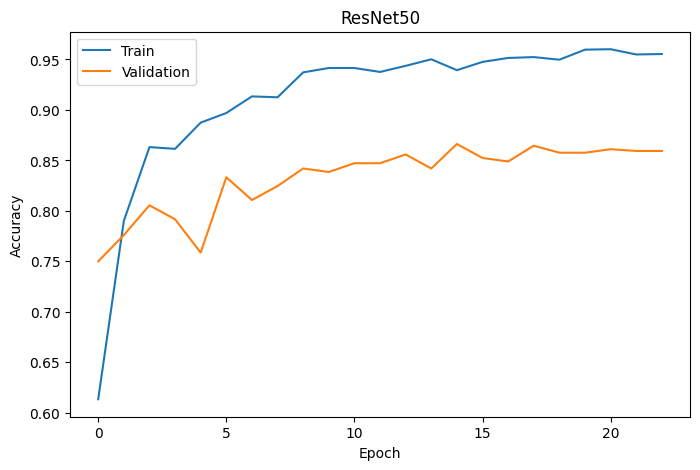

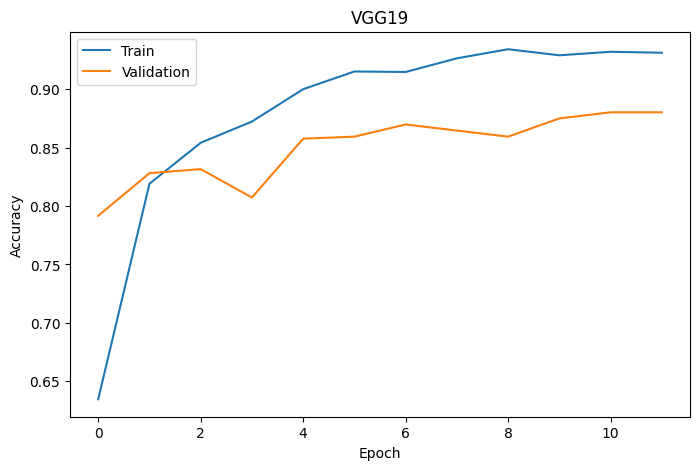

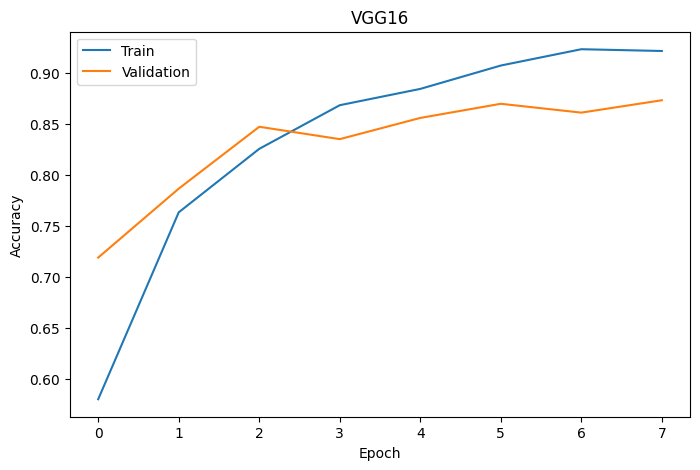

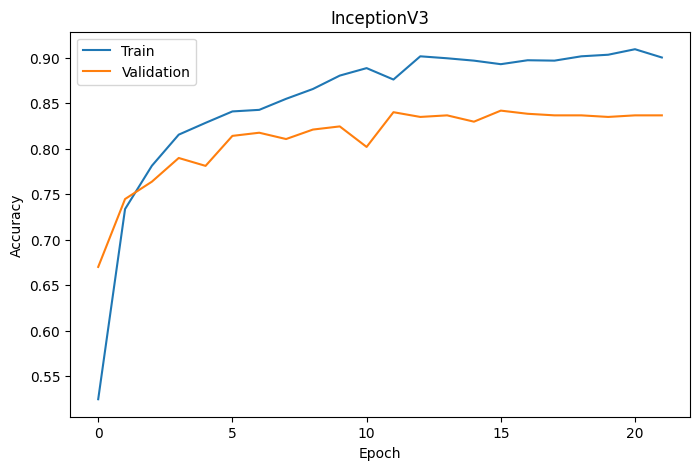

In [17]:
for model_name, history in histories.items():
    plt.figure(figsize=(8, 5))

    plt.plot(history.history["accuracy"], label="Train")
    plt.plot(history.history["val_accuracy"], label="Validation")

    plt.title(model_name)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

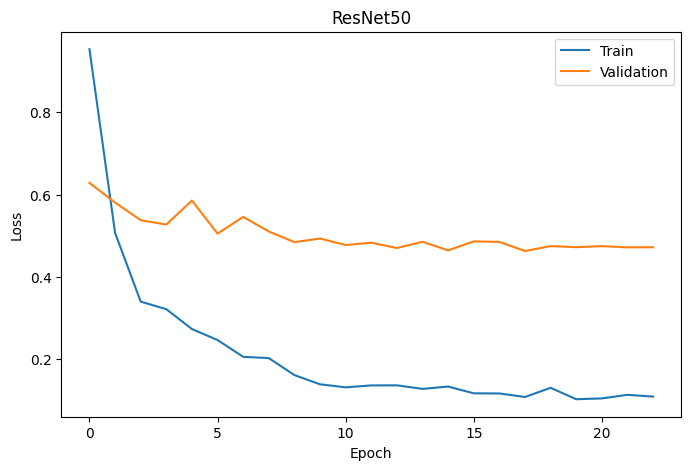

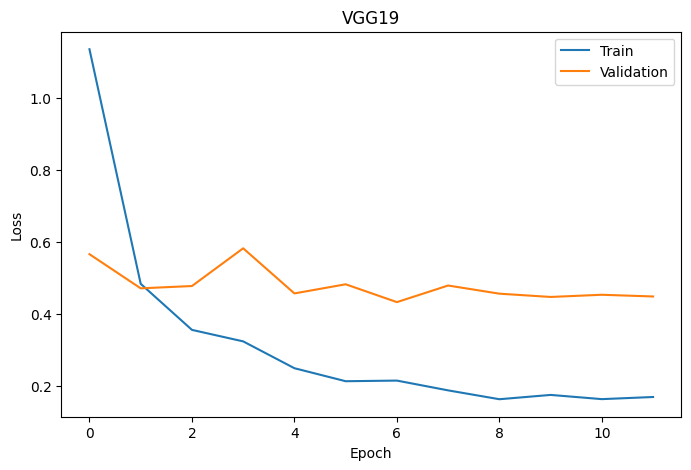

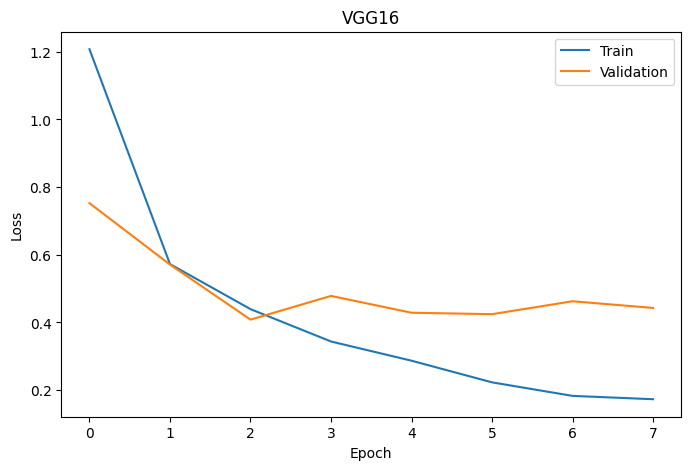

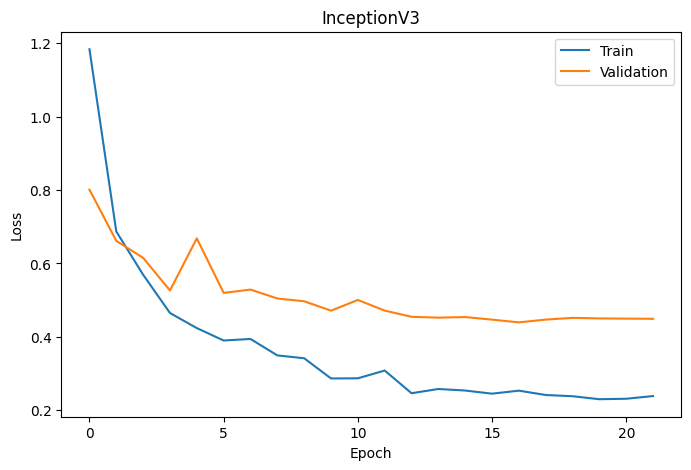

In [18]:
for model_name, history in histories.items():
    plt.figure(figsize=(8, 5))

    plt.plot(history.history["loss"], label="Train")
    plt.plot(history.history["val_loss"], label="Validation")

    plt.title(model_name)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

In [19]:
for model_name in models:
    print(
        f"{model_name}: "
        f"Accuracy = {test_results[model_name]['accuracy']:.4f}, "
        f"Macro F1 = {reports[model_name]['macro avg']['f1-score']:.4f}"
    )

ResNet50: Accuracy = 0.6827, Macro F1 = 0.6416
VGG19: Accuracy = 0.6980, Macro F1 = 0.6592
VGG16: Accuracy = 0.7081, Macro F1 = 0.6798
InceptionV3: Accuracy = 0.7183, Macro F1 = 0.6942


In [20]:
import os

save_path = "/content/drive/MyDrive/AI Course2/HW 2-13/saved_models"
os.makedirs(save_path, exist_ok=True)

In [21]:
for model_name, model in models.items():
    model.save(f"{save_path}/{model_name}.keras")

In [22]:
import pickle

with open(f"{save_path}/histories.pkl", "wb") as f:
    pickle.dump(histories, f)

In [23]:
with open(f"{save_path}/evaluation_results.pkl", "wb") as f:
    pickle.dump({
        "test_results": test_results,
        "reports": reports
    }, f)